# **Customer Churn Prediction & Retention Strategy**
## AI for Communication and Marketing - Lab Exam Part 2
### Academic Year 2025/2026 | B.Sc. in Artificial Intelligence

---

**Student:** Daria Miele  
**Matricola:** 535702 

---
### Business Context
Customer churn — the decision by an existing customer to stop purchasing from 
a platform — is one of the most costly problems in e-commerce. Acquiring a new 
customer typically costs five to seven times more than retaining an existing one, 
making churn prevention a direct lever on profitability.

This project addresses the following business question: given historical data on 
customer behaviour, demographics, and transaction patterns, can we identify 
which customers are most likely to churn — and why?

The dataset provided by the Marketing department contains 5,630 customer records 
with 19 features covering tenure, purchase behaviour, satisfaction, complaint 
history, and cashback. The target variable `Churn` is a binary flag indicating 
whether a customer has churned.

The deliverable is a propensity model that assigns each customer a churn 
probability score, enabling the Marketing team to prioritise retention 
interventions toward the customers most at risk — before they leave.

---
## **Setup & Library Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Global style
sns.set_theme(style="whitegrid", palette="muted")
PALETTE = {"0": "#4C72B0", "1": "#DD8452"}
CHURN_COLORS = [PALETTE["0"], PALETTE["1"]]
DPI = 150
SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

---
## **Data Audit & Quality**

This section loads the raw dataset, documents its structure, identifies missing values and outliers, and prepares a clean, encoded version ready for modelling. 

### 1.1 Initial Inspection
We load the raw Excel file and display the first five rows to confirm the file 
was read correctly, verify column names, and get a first visual impression of 
the data.

In [18]:
df_raw = pd.read_excel("../data/data.xlsx")
df_raw.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001.00,1,4.00,Mobile Phone,3,6.00,Debit Card,Female,3.00,3,Laptop & Accessory,2,Single,9,1,11.00,1.00,1.00,5.00,159.93
1,50002.00,1,NaN,Phone,1,8.00,UPI,Male,3.00,4,Mobile,3,Single,7,1,15.00,0.00,1.00,0.00,120.90
2,50003.00,1,NaN,Phone,1,30.00,Debit Card,Male,2.00,4,Mobile,3,Single,6,1,14.00,0.00,1.00,3.00,120.28
3,50004.00,1,0.00,Phone,3,15.00,Debit Card,Male,2.00,4,Laptop & Accessory,5,Single,8,0,23.00,0.00,1.00,3.00,134.07
4,50005.00,1,0.00,Phone,1,12.00,CC,Male,NaN,3,Mobile,5,Single,3,0,11.00,1.00,1.00,3.00,129.60


We establish the exact dimensions of the dataset and inspect the data type for each column. 

In [19]:
print(f"Rows: {df_raw.shape[0]}  |  Columns: {df_raw.shape[1]}")
print()
df_raw.dtypes.to_frame(name="dtype")

Rows: 5630  |  Columns: 20



,dtype
CustomerID,float64
Churn,int64
Tenure,float64
PreferredLoginDevice,str
CityTier,int64
WarehouseToHome,float64
PreferredPaymentMode,str
Gender,str
HourSpendOnApp,float64
NumberOfDeviceRegistered,int64


The dataset contains 5,630 rows and 20 columns. Eleven features are numerical 
(float64 or int64) and five are string-type categorical. 

### 1.2 Target Variable Distribution

Before auditing the features, we inspect the distribution of the target variable 
`Churn` to understand the class balance of the dataset. 

In [28]:
churn_counts = df_raw["Churn"].value_counts().rename({0: "Non-Churner", 1: "Churner"})
churn_pct = (churn_counts / len(df_raw) * 100).round(2)
pd.DataFrame({"Count": churn_counts, "Percentage (%)": churn_pct})

,Count,Percentage (%)
Churn,,
Non-Churner,4682,83.16
Churner,948,16.84


The dataset is significantly imbalanced: 4,682 customers (83.16%) are labelled 
as non-churners and only 948 (16.84%) as churners. A naive classifier that 
predicts "no churn" for every customer would already achieve 83% accuracy, making 
accuracy a misleading evaluation metric. 

### 1.3  Missing Value Audit

We count the absolute and relative number of missing values in every column, 
sorted by severity. 

In [20]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes,
    "missing_n": df_raw.isnull().sum(),
    "missing_pct": (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    "unique": df_raw.nunique()
}).sort_values("missing_pct", ascending=False)

audit.style.background_gradient(subset=["missing_pct"], cmap="YlOrRd")

,dtype,missing_n,missing_pct,unique
DaySinceLastOrder,float64,307,5.450000,22
OrderAmountHikeFromlastYear,float64,265,4.710000,16
Tenure,float64,264,4.690000,36
OrderCount,float64,258,4.580000,16
CouponUsed,float64,256,4.550000,17
HourSpendOnApp,float64,255,4.530000,6
WarehouseToHome,float64,251,4.460000,34
CustomerID,float64,2,0.040000,5628
Gender,str,2,0.040000,2
Churn,int64,0,0.000000,2


Seven numerical columns carry missing values, all clustered between 4.46% and 
5.45% missingness. `DaySinceLastOrder` is the most affected at 5.45% (307 missing 
rows), followed by `OrderAmountHikeFromlastYear` at 4.71% (265), `Tenure` at 4.69% 
(264), `OrderCount` at 4.58% (258), `CouponUsed` at 4.55% (256), `HourSpendOnApp` 
at 4.53% (255), and `WarehouseToHome` at 4.46% (251). `CustomerID` and `Gender` 
each show only 2 missing values (0.04%). 

The target variable `Churn` and all remaining columns are fully observed. No column exceeds 6% missingness, so removal of entire columns is not warranted.

### 1.4 Duplicate Row Check

We verify whether the dataset contains any exact duplicate rows. Duplicates 
would artificially inflate the training set and bias the model toward repeated 
observations.

In [29]:
n_duplicates = df_raw.duplicated().sum()
print(f"Duplicate rows: {n_duplicates}")

Duplicate rows: 0


No duplicate rows were found in the dataset. Every record represents a distinct 
customer observation and no deduplication is required.

### 1.5 Categorical Label Inspection

We inspect the raw unique labels in every categorical column. Inconsistent naming 
conventions or strings used as placeholders for missing data would distort both 
the missing value count from Section 1.4 and the eventual encoding.

In [23]:
cat_cols_raw = df_raw.select_dtypes(include="str").columns.tolist()
for col in cat_cols_raw:
    vals = sorted(df_raw[col].dropna().unique())
    print(f"{col} ({len(vals)} unique): {vals}")

PreferredLoginDevice (4 unique): ['Computer', 'Mobile Phone', 'N.A.', 'Phone']
PreferredPaymentMode (7 unique): ['CC', 'COD', 'Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
Gender (2 unique): ['Female', 'Male']
PreferedOrderCat (6 unique): ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile', 'Mobile Phone', 'Others']
MaritalStatus (4 unique): ['Divorced', 'Married', 'Single', 'Widow']


The inspection reveals some data quality issues in the categorical columns. 
- `PreferredLoginDevice` reports 4 unique values including "N.A.", which is not a 
device type but a string placeholder for a missing value. 
- `PreferredPaymentMode` reports 7 unique values, but "CC" and "Credit Card" refer 
to the same payment method, as do "COD" and "Cash on Delivery" — reducing the true 
number of distinct categories to 5. 
- `PreferedOrderCat` shows "Mobile" and "Mobile Phone" as separate labels, which may also be duplicates and will require clarification. 
- `Gender` and `MaritalStatus` show clean, consistent labels with no  anomalies.

### 1.6 Outlier Inspection

We now examine numerical columns that represent physically bounded quantities. 
`WarehouseToHome` (distance in km) and `Tenure` (months of membership) have 
natural upper limits in any realistic e-commerce context. We also inspect 
`CashbackAmount`, whose high unique count warrants a closer look at its range. 
Boxplots make extreme values immediately visible; the descriptive statistics 
quantify them precisely.

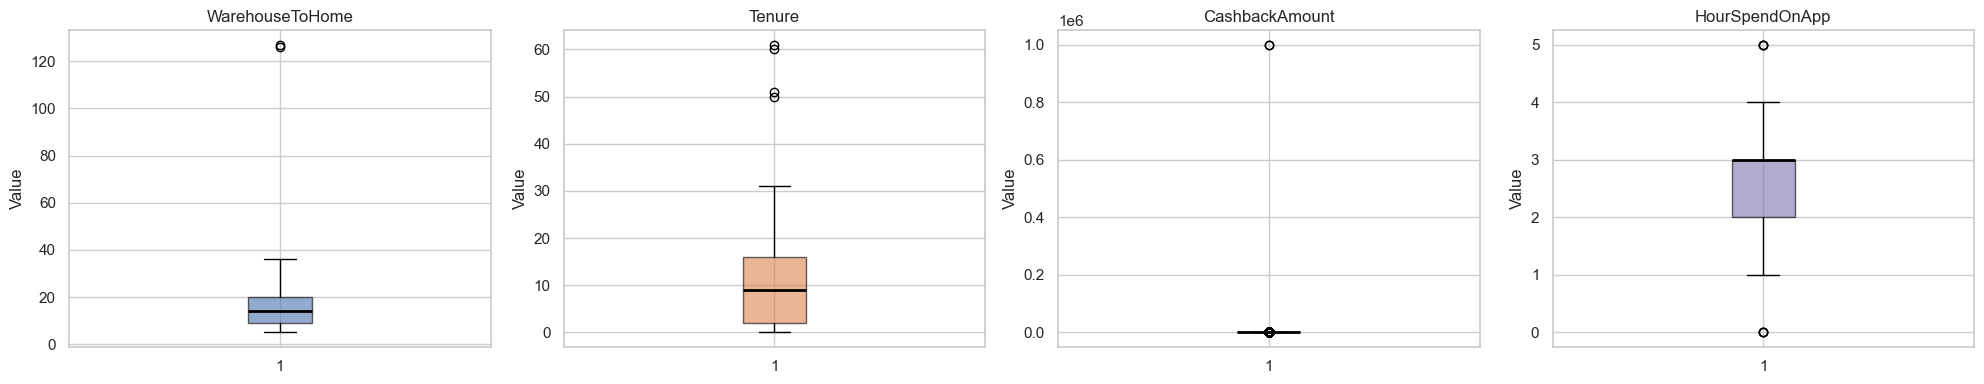

,WarehouseToHome,Tenure,CashbackAmount,HourSpendOnApp
count,5379.00,5366.00,5630.00,5375.00
mean,15.64,10.19,532.40,2.93
std,8.53,8.56,18842.84,0.72
min,5.00,0.00,0.00,0.00
25%,9.00,2.00,145.77,2.00
50%,14.00,9.00,163.33,3.00
75%,20.00,16.00,196.42,3.00
max,127.00,61.00,999999.00,5.00


In [30]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, col, color in zip(
    axes,
    ["WarehouseToHome", "Tenure", "CashbackAmount", "HourSpendOnApp"],
    CHURN_COLORS + ["#55A868", "#8172B2"]
):
    ax.boxplot(df_raw[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color="black", linewidth=2))
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.savefig("outliers_boxplot.png", dpi=DPI, bbox_inches="tight")
plt.show()

df_raw[["WarehouseToHome", "Tenure", "CashbackAmount", "HourSpendOnApp"]].describe()

The boxplots reveal extreme outliers in all three inspected columns. 
- `WarehouseToHome` has a median of 14 km and a 75th percentile of 20 km, but 
reaches a maximum of 127 km — a single point more than three times the upper 
quartile. 
- `Tenure` has a median of 9 months and a 75th percentile of 16 months, yet reaches 61 months with two isolated points above 50 — inconsistent with the distribution of the rest of the column. 
- `CashbackAmount` is the most severe case: the mean is 532.40 with a standard deviation of 18,842 against a median of just 163.33, and the maximum is 
exactly 999,999 — a value that cannot represent a real cashback amount and is 
recognisable as a sentinel value used in operational databases to encode missing 
records.

### 1.7 Pre-Capping Percentile Analysis

The boxplots in 1.6 show isolated extreme values in `WarehouseToHome` and 
`Tenure`. Before deciding on a capping threshold, we compute the 75th and 99th 
percentiles alongside the observed maximum for both columns. This gives us a 
precise, data-driven justification for where the cap is placed.

In [32]:
percentile_data = []
for col in ["WarehouseToHome", "Tenure"]:
    percentile_data.append({
        "Column": col,
        "75th Percentile": df_raw[col].quantile(0.75),
        "99th Percentile": df_raw[col].quantile(0.99),
        "Max": df_raw[col].max()
    })

pd.DataFrame(percentile_data).set_index("Column")

,75th Percentile,99th Percentile,Max
Column,,,
WarehouseToHome,20.00,35.00,127.00
Tenure,16.00,30.00,61.00


For `WarehouseToHome`, the 99th percentile is 35 km against an observed maximum 
of 127 km — a gap of 92 km that is not part of a continuous distribution but 
rather a cluster of isolated extreme values. For `Tenure`, the 99th percentile 
is 30 months against an observed maximum of 61 months. In both cases, the 99th 
percentile represents a natural boundary beyond which values are implausible in 
an e-commerce context. Capping at this threshold preserves 99% of the 
distribution while eliminating the distorting effect of the extreme tail.

### 1.8 Cleaning 

The audit performed reveals the following issues. 
Each decision below is directly traceable to a specific finding above.

- **`CustomerID` dropped**: confirmed as a float identifier with 5,628 
  near-unique values — no predictive signal.
- **Seven numerical columns imputed with median**: missingness ranges from 4.46% 
  to 5.45% — too substantial to ignore, but far below the threshold for dropping columns. Median is preferred over mean because the outlier inspection in 1.6 shows skewed distributions in several of these columns, making the median a more robust central tendency estimate.
- **`Gender` rows dropped**: only 2 rows missing. 
  Imputing a binary demographic attribute from unrelated features introduces 
  unsupported assumptions; dropping 2 rows has negligible impact on the dataset.
- **`PreferredLoginDevice` "N.A." replaced with mode**: confirmed as a 
  string placeholder for a missing value, not captured by the null audit because 
  it was stored as a non-null string.
- **`PreferredPaymentMode` consolidated from 7 to 5 categories**: confirmed in 
  1.5 that "CC"/"Credit Card" and "COD"/"Cash on Delivery" are duplicate labels.
- **`WarehouseToHome` capped at 35 km (99th percentile)**: 1.7 shows the 99th 
  percentile is 35 km against a maximum of 127 km — a gap of 92 km driven by 
  isolated implausible values.
- **`Tenure` capped at 30 months (99th percentile)**: 1.7 shows the 99th 
  percentile is 30 months against a maximum of 61 months.
- **`CashbackAmount` sentinel value replaced**: 1.6 confirmed a maximum of 
  999,999 against a median of 163.33. Replaced with the median of valid 
  observations only.
- **`HourSpendOnApp` left unchanged**: 1.6 confirmed a clean distribution 
  ranging from 0 to 5 with no anomalous values.
- **No duplicate rows to remove**: confirmed in 1.4.

In [34]:
df = df_raw.copy()

# Drop identifier column
df = df.drop(columns=["CustomerID"])

# Impute numerical missings with median
num_cols_missing = [
    "Tenure", "WarehouseToHome", "HourSpendOnApp",
    "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount", "DaySinceLastOrder"
]
for col in num_cols_missing:
    df[col] = df[col].fillna(df[col].median())

# Drop rows with missing Gender
df = df.dropna(subset=["Gender"])

# Replace disguised missing in PreferredLoginDevice
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace("N.A.", np.nan)
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].fillna(
    df["PreferredLoginDevice"].mode()[0]
)

# Consolidate duplicate payment labels
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({
    "COD": "Cash on Delivery",
    "CC": "Credit Card"
})

# Cap WarehouseToHome and Tenure at 99th percentile
for col in ["WarehouseToHome", "Tenure"]:
    cap = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=cap)

# Replace CashbackAmount sentinel value with median of valid observations
cb_median = df.loc[df["CashbackAmount"] < 999999, "CashbackAmount"].median()
df["CashbackAmount"] = df["CashbackAmount"].replace(999999, cb_median)

print(f"Rows after cleaning: {len(df)}")
print(f"Remaining nulls: {df.isnull().sum().sum()}")

Rows after cleaning: 5628
Remaining nulls: 0


We verify every transformation applied. The three numerically treated columns are re-described to confirm their ranges are now coherent, and the labels of the two consolidated categorical columns are printed to confirm no spurious categories remain.

In [35]:
display(df[["WarehouseToHome", "Tenure", "CashbackAmount"]].describe()
        .style.background_gradient(cmap="Blues"))

for col in ["PreferredLoginDevice", "PreferredPaymentMode"]:
    print(f"{col}: {sorted(df[col].unique())}")

,WarehouseToHome,Tenure,CashbackAmount
count,5628.000000,5628.000000,5628.000000
mean,15.522210,10.108031,177.227525
std,8.064034,8.265222,49.213043
min,5.000000,0.000000,0.000000
25%,9.000000,3.000000,145.770000
50%,14.000000,9.000000,163.280000
75%,20.000000,15.000000,196.400000
max,35.000000,30.000000,324.990000


PreferredLoginDevice: ['Computer', 'Mobile Phone', 'Phone']
PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']


All three numerical columns now show clean, coherent ranges. `WarehouseToHome` is 
bounded between 5 and 35 km, `Tenure` between 0 and 30 months, and 
`CashbackAmount` between 0 and 324.99 with a mean of 177.23 and a standard 
deviation of 49.21 — confirming the sentinel value of 999,999 has been 
successfully replaced. `PreferredLoginDevice` now contains exactly 3 categories 
(Computer, Mobile Phone, Phone), with the "N.A." placeholder eliminated. 
`PreferredPaymentMode` now contains exactly 5 categories (Cash on Delivery, Credit 
Card, Debit Card, E wallet, UPI), with the duplicate abbreviations consolidated.

### 1.9 Categorical Encoding

All five string-type features are now label-encoded into integer values for 
machine learning compatibility. The complete mapping for each column is documented 
in the table below for full traceability.

In [36]:
cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
            "PreferedOrderCat", "MaritalStatus"]

df_encoded = df.copy()
le = LabelEncoder()
encoding_map = {}

for col in cat_cols:
    df_encoded[col] = le.fit_transform(df[col])
    encoding_map[col] = dict(zip(le.classes_, le.transform(le.classes_)))

enc_df = pd.DataFrame([
    {"Column": col, "Original": k, "Encoded": v}
    for col, mapping in encoding_map.items()
    for k, v in mapping.items()
])
enc_df.style.background_gradient(subset=["Encoded"], cmap="Blues")

,Column,Original,Encoded
0,PreferredLoginDevice,Computer,0
1,PreferredLoginDevice,Mobile Phone,1
2,PreferredLoginDevice,Phone,2
3,PreferredPaymentMode,Cash on Delivery,0
4,PreferredPaymentMode,Credit Card,1
5,PreferredPaymentMode,Debit Card,2
6,PreferredPaymentMode,E wallet,3
7,PreferredPaymentMode,UPI,4
8,Gender,Female,0
9,Gender,Male,1


Five categorical columns have been successfully label-encoded. 
`PreferredLoginDevice` maps to 3 integer classes, `PreferredPaymentMode` to 5, 
`Gender` to 2 (Female = 0, Male = 1), `PreferedOrderCat` to 6, and `MaritalStatus` 
to 4. 

### 1.10 Final Dataset Overview

We close the section with a complete descriptive summary of the cleaned and 
encoded dataset to confirm that all columns are fully populated and all value ranges are coherent.

In [37]:
df_encoded.describe().style.background_gradient(cmap="Blues")

,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000,5628.000000
mean,0.168443,10.108031,0.928749,1.654584,15.522210,1.758351,0.601102,2.934613,3.688877,2.369758,3.067164,1.169332,4.214463,0.284826,15.674662,1.717484,2.962509,4.460199,177.227525
std,0.374293,8.265222,0.709481,0.915335,8.064034,1.012570,0.489715,0.705652,1.024164,1.411669,1.380164,0.665698,2.583874,0.451372,3.591385,1.857688,2.879522,3.570760,49.213043
min,0.000000,0.000000,0.000000,1.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,0.000000,3.000000,0.000000,1.000000,9.000000,1.000000,0.000000,2.000000,3.000000,2.000000,2.000000,1.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,0.000000,9.000000,1.000000,1.000000,14.000000,2.000000,1.000000,3.000000,4.000000,2.000000,3.000000,1.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,0.000000,15.000000,1.000000,3.000000,20.000000,2.000000,1.000000,3.000000,4.000000,4.000000,4.000000,2.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.400000
max,1.000000,30.000000,2.000000,3.000000,35.000000,4.000000,1.000000,5.000000,6.000000,5.000000,5.000000,3.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000


The cleaned and encoded dataset contains 5,628 rows and 19 columns, all with a 
count of 5,628 — confirming zero missing values remain. All value ranges are 
coherent with their domain: `Churn` is binary with a mean of 0.168, indicating 
that approximately 16.8% of customers are labelled as churners. `SatisfactionScore` 
ranges from 1 to 5, `CityTier` from 1 to 3, and `NumberOfDeviceRegistered` from 1 
to 6, all consistent with their expected scales. 

---
## **Exploratory Data Analysis**
With a clean and encoded dataset in hand, we now explore the relationships 
between the features and the target variable `Churn`. The goal is to identify 
patterns and signals that will inform both the modelling choices 
and the marketing recommendations in the next sections.

### 2.1 Class Balance

We already measured the raw churn rate in Section 1.3. Here we visualise the 
class distribution to make the imbalance immediately apparent, and quantify its 
implications for modelling.

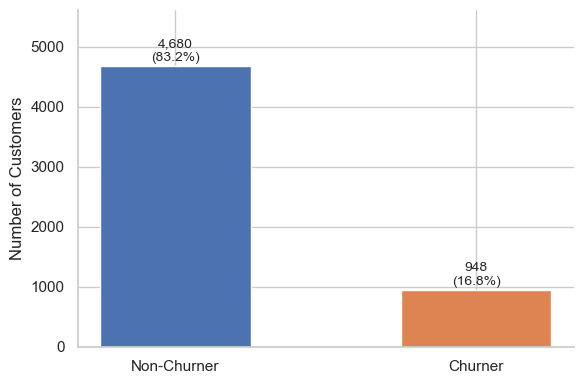

In [44]:
churn_counts = df_encoded["Churn"].value_counts().rename({0: "Non-Churner", 1: "Churner"})

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index, churn_counts.values,
              color=CHURN_COLORS, edgecolor="white", width=0.5)

for bar, val in zip(bars, churn_counts.values):
    pct = val / len(df_encoded) * 100
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 30,
            f"{val:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10)

ax.set_ylabel("Number of Customers")
ax.set_ylim(0, churn_counts.max() * 1.2)
ax.set_title("")
sns.despine()
plt.tight_layout()
plt.savefig("class_balance.png", dpi=DPI, bbox_inches="tight")
plt.show()

The dataset is heavily skewed toward non-churners: 4,680 customers (83.2%) 
remain active while only 948 (16.8%) have churned. This imbalance means that 
a trivial model predicting "no churn" for every customer would already achieve 
83% accuracy — making accuracy a meaningless metric for this problem. Recall 
will be the primary evaluation criterion in Section 3, as the business cost of 
missing a churner far exceeds the cost of incorrectly flagging a loyal customer.

### 2.2 Correlation: Complain, SatisfactionScore, and Churn

We analyse the relationship between `Complain`, `SatisfactionScore`, and `Churn` 
using two complementary approaches. First, a heatmap shows the pairwise 
Pearson correlations among these three variables. Second, bar charts show the 
actual churn rate broken down by each category, making the business implication 
of each relationship directly readable.

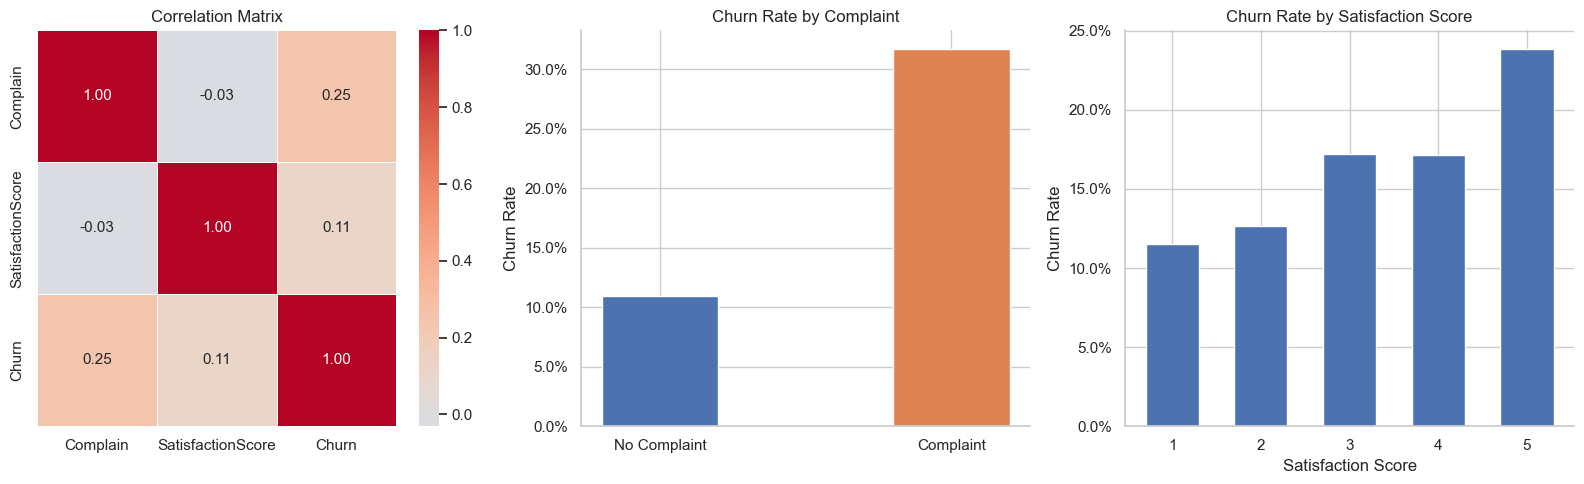

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Heatmap
corr = df_encoded[["Complain", "SatisfactionScore", "Churn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=axes[0],
            annot_kws={"size": 11})
axes[0].set_title("Correlation Matrix")

# Churn rate by Complain
complain_churn = df_encoded.groupby("Complain")["Churn"].mean().reset_index()
complain_churn["Complain"] = complain_churn["Complain"].map({0: "No Complaint", 1: "Complaint"})
axes[1].bar(complain_churn["Complain"], complain_churn["Churn"],
            color=CHURN_COLORS, edgecolor="white", width=0.4)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[1].set_ylabel("Churn Rate")
axes[1].set_title("Churn Rate by Complaint")
sns.despine(ax=axes[1])

# Churn rate by SatisfactionScore
sat_churn = df_encoded.groupby("SatisfactionScore")["Churn"].mean().reset_index()
axes[2].bar(sat_churn["SatisfactionScore"], sat_churn["Churn"],
            color="#4C72B0", edgecolor="white", width=0.6)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[2].set_xlabel("Satisfaction Score")
axes[2].set_ylabel("Churn Rate")
axes[2].set_title("Churn Rate by Satisfaction Score")
sns.despine(ax=axes[2])

plt.tight_layout()
plt.savefig("complain_satisfaction_churn.png", dpi=DPI, bbox_inches="tight")
plt.show()

The correlation matrix shows that `Complain` has the strongest linear 
relationship with `Churn` among the three variables, with a Pearson coefficient 
of 0.25. `SatisfactionScore` shows a weaker positive correlation of 0.11, and 
the two predictors are nearly uncorrelated with each other (-0.03), confirming 
they capture independent dimensions of customer experience. 

The bar charts make 
the practical magnitude of these relationships concrete: customers who filed a 
complaint churn at 32%, nearly three times the rate of those who did not (11%). 
The relationship with `SatisfactionScore` is counterintuitive — churn rate 
increases with score, reaching 24% at score 5 compared to 11% at score 1. 

### 2.3 Churn Rate Deep Dive: Complain and SatisfactionScore

The correlation matrix in Section 2.2 quantified the linear relationships. 
Here we extract the exact churn rates for each category of `Complain` and 
`SatisfactionScore` individually, then examine whether the two variables 
interact — specifically, whether the upward trend in churn rate across 
satisfaction scores is genuine or driven by the presence of complaints.

In [54]:
# Churn rate by Complain
complain_rate = (df_encoded.groupby("Complain")["Churn"]
                 .mean()
                 .rename(index={0: "No Complaint", 1: "Complaint"})
                 .to_frame("Churn Rate"))

# Churn rate by SatisfactionScore
sat_rate = (df_encoded.groupby("SatisfactionScore")["Churn"]
            .mean()
            .to_frame("Churn Rate"))

# Interaction pivot
pivot = df_encoded.groupby(
    ["SatisfactionScore", "Complain"]
)["Churn"].mean().unstack()
pivot.columns = ["No Complaint", "Complaint"]

display(complain_rate.style.format("{:.1%}").background_gradient(cmap="YlOrRd"))
display(sat_rate.style.format("{:.1%}").background_gradient(cmap="YlOrRd"))
display(pivot.style.format("{:.1%}").background_gradient(cmap="YlOrRd"))

,Churn Rate
Complain,
No Complaint,10.9%
Complaint,31.7%


,Churn Rate
SatisfactionScore,
1,11.5%
2,12.6%
3,17.2%
4,17.1%
5,23.8%


,No Complaint,Complaint
SatisfactionScore,,
1,7.1%,21.0%
2,7.7%,24.7%
3,10.4%,34.7%
4,9.9%,38.8%
5,18.3%,37.3%


The three tables together tell a coherent story. 
- Customers who filed a complaint 
churn at 31.7% — nearly three times the rate of those who did not (10.9%). 
- `SatisfactionScore` alone shows a gradual upward trend from 11.5% at score 1 
to 23.8% at score 5, which appears counterintuitive at first glance.

- The interaction pivot resolves this: among customers without a complaint, churn 
rates are stable between 7.1% and 10.4% across scores 1 through 4, with a jump 
only at score 5. Among customers with a complaint, churn escalates 
consistently from 21.0% at score 1 to a peak of 38.8% at score 4, remaining 
high at 37.3% at score 5. 

The upward trend in the aggregate satisfaction score 
analysis is therefore a composition effect: it is driven entirely by the 
complaint subgroup, not by a genuine relationship between satisfaction and churn. 
`Complain` is the dominant signal; `SatisfactionScore` adds limited independent 
information once complaint status is known.

### 2.4 Distribution of Tenure and DaySinceLastOrder by Churn Status

Before grouping customers into bands, we visualise the full continuous 
distributions of `Tenure` and `DaySinceLastOrder` separately for churners 
and non-churners. This reveals where the two groups diverge most clearly 
along each variable.

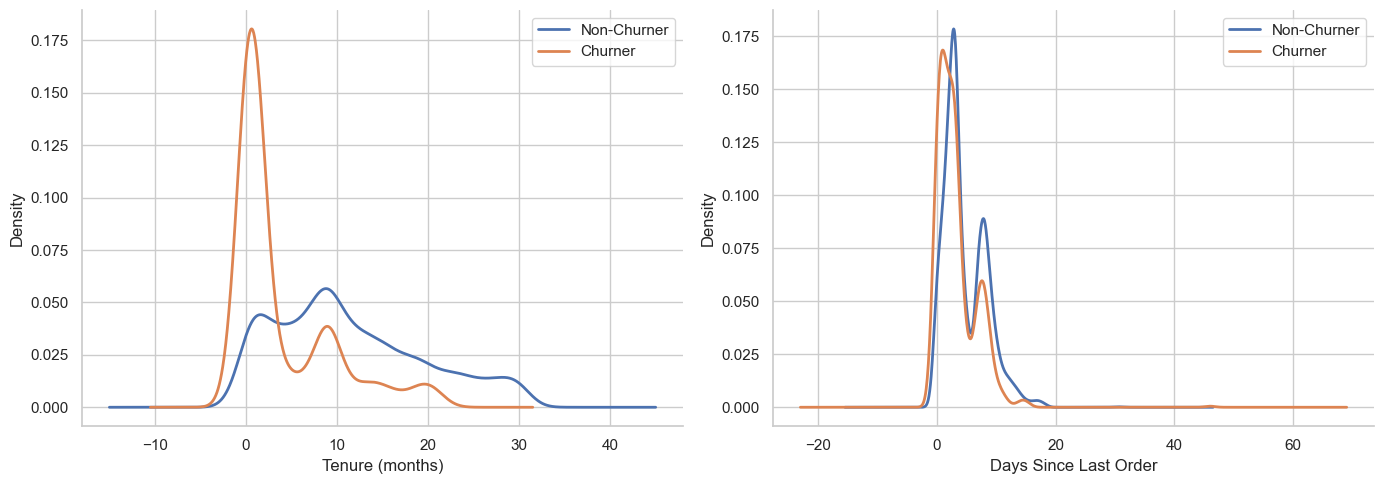

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, title in zip(
    axes,
    ["Tenure", "DaySinceLastOrder"],
    ["Tenure (months)", "Days Since Last Order"]
):
    for churn_val, label, color in zip([0, 1], ["Non-Churner", "Churner"], CHURN_COLORS):
        subset = df_encoded[df_encoded["Churn"] == churn_val][col]
        subset.plot.kde(ax=ax, label=label, color=color, linewidth=2)
    ax.set_xlabel(title)
    ax.set_ylabel("Density")
    ax.legend()
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("tenure_recency_kde.png", dpi=DPI, bbox_inches="tight")
plt.show()

For `Tenure`, the churner distribution is sharply concentrated 
near zero, with a peak between 0 and 2 months and density falling 
rapidly beyond 10 months. The non-churner distribution is broader and flatter, 
spreading across the full tenure range with notable mass between 5 and 30 months. 
This indicates that churn is a phenomenon concentrated in the earliest months of the customer 
relationship. 

For `DaySinceLastOrder`, the two distributions largely overlap, 
both peaking near 0–3 days and declining sharply. The churner distribution shows 
slightly less mass in the 5–20 day range compared to non-churners, but the 
separation is far less pronounced than for `Tenure`. 

### 2.5 Churn Probability by Tenure

We visualise how the probability of churning changes as a function of customer 
tenure. Customers are grouped into tenure bands and the churn rate is computed 
for each band, revealing whether newer or more established customers are at 
higher risk.

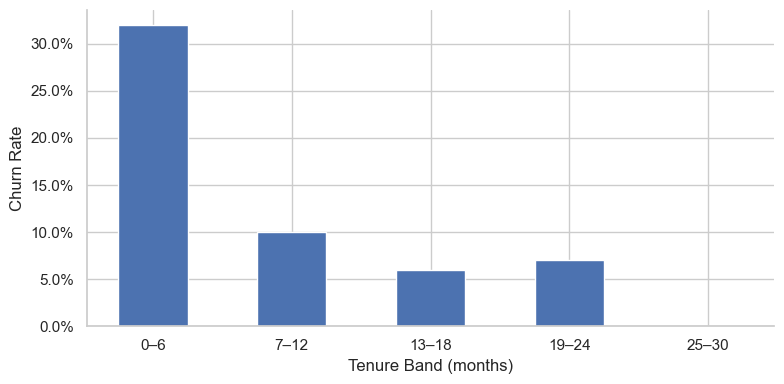

,Churn_Rate,N
TenureBand,,
0–6,0.32,2149
7–12,0.10,1584
13–18,0.06,893
19–24,0.07,573
25–30,0.00,429


In [50]:
df_encoded["TenureBand"] = pd.cut(df_encoded["Tenure"],
                                   bins=[0, 6, 12, 18, 24, 30],
                                   labels=["0–6", "7–12", "13–18", "19–24", "25–30"],
                                   include_lowest=True)

tenure_stats = df_encoded.groupby("TenureBand", observed=True)["Churn"].agg(
    Churn_Rate="mean", N="count"
).round({"Churn_Rate": 2})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tenure_stats.index.astype(str), tenure_stats["Churn_Rate"],
       color="#4C72B0", edgecolor="white", width=0.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Tenure Band (months)")
ax.set_ylabel("Churn Rate")
sns.despine()
plt.tight_layout()
plt.savefig("tenure_churn.png", dpi=DPI, bbox_inches="tight")
plt.show()

tenure_stats

Tenure is a strong discriminator of churn risk. These resukts clearly show that churn is concentrated in the early stages of the customer relationship, 
before loyalty is established.

Customers in their first six months churn at 32% — more than three times the rate of those with 7 to 12 months of tenure (10%). The rate continues to decline with 
tenure: 6% between 13 and 18 months and 7% between 19 and 24 months . The 25–30 month band shows a churn rate of 0% across 429 customers, 
a result that is statistically meaningful given the sample size and suggests 
that customers who remain on the platform beyond two years do not churn. 

### 2.6 Churn Probability by Days Since Last Order

We apply the same approach to `DaySinceLastOrder`, grouping customers by 
recency of their last purchase and computing the churn rate per band. This 
reveals whether customer inactivity is a reliable signal of churn risk.

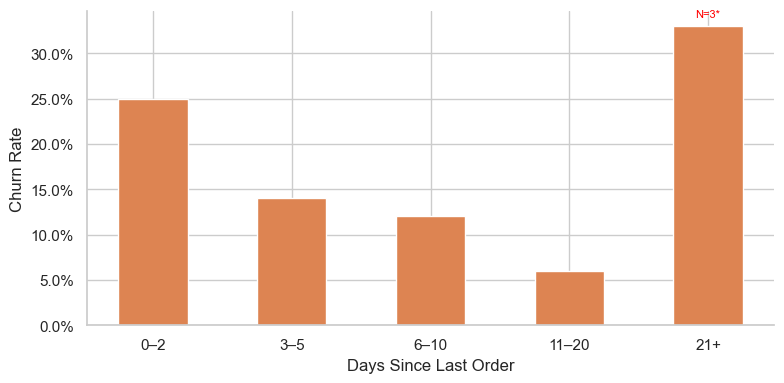

,Churn_Rate,N
RecencyBand,,
0–2,0.25,1901
3–5,0.14,1865
6–10,0.12,1554
11–20,0.06,305
21+,0.33,3


In [52]:
df_encoded["RecencyBand"] = pd.cut(df_encoded["DaySinceLastOrder"],
                                    bins=[-1, 2, 5, 10, 20, 46],
                                    labels=["0–2", "3–5", "6–10", "11–20", "21+"])

recency_stats = df_encoded.groupby("RecencyBand", observed=True)["Churn"].agg(
    Churn_Rate="mean", N="count"
).round({"Churn_Rate": 2})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(recency_stats.index.astype(str), recency_stats["Churn_Rate"],
       color="#DD8452", edgecolor="white", width=0.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Days Since Last Order")
ax.set_ylabel("Churn Rate")

# Annotate bands with N < 30 as unreliable
for i, (band, row) in enumerate(recency_stats.iterrows()):
    if row["N"] < 30:
        ax.text(i, row["Churn_Rate"] + 0.01, f"N={int(row['N'])}*",
                ha="center", fontsize=8, color="red")
        
sns.despine()
plt.tight_layout()
plt.savefig("recency_churn.png", dpi=DPI, bbox_inches="tight")
plt.show()

recency_stats

The recency analysis requires careful interpretation in light of the band 
counts. The bands 0–2 days (N=1,901), 3–5 days (N=1,865), and 6–10 days 
(N=1,554) all have substantial samples and show a clear declining pattern: 
churn rates of 25%, 14%, and 12% respectively. The 11–20 day band shows the 
lowest churn rate at 6%, based on 305 customers. The 21+ day band shows the 
highest churn rate of 33%, but is based on only 3 customers — this figure is 
not statistically reliable and cannot be used to draw conclusions about 
long-term inactivity. 

The actionable finding from this analysis is the 
declining trend across the first three bands: customers who ordered within 
the last two days are more than twice as likely to churn as those who ordered 
6 to 10 days ago.

### 2.7 Full Correlation Heatmap

We close the EDA with a full correlation heatmap across all encoded features 
to identify any additional variables with meaningful linear relationships to 
`Churn`, beyond those already examined individually.

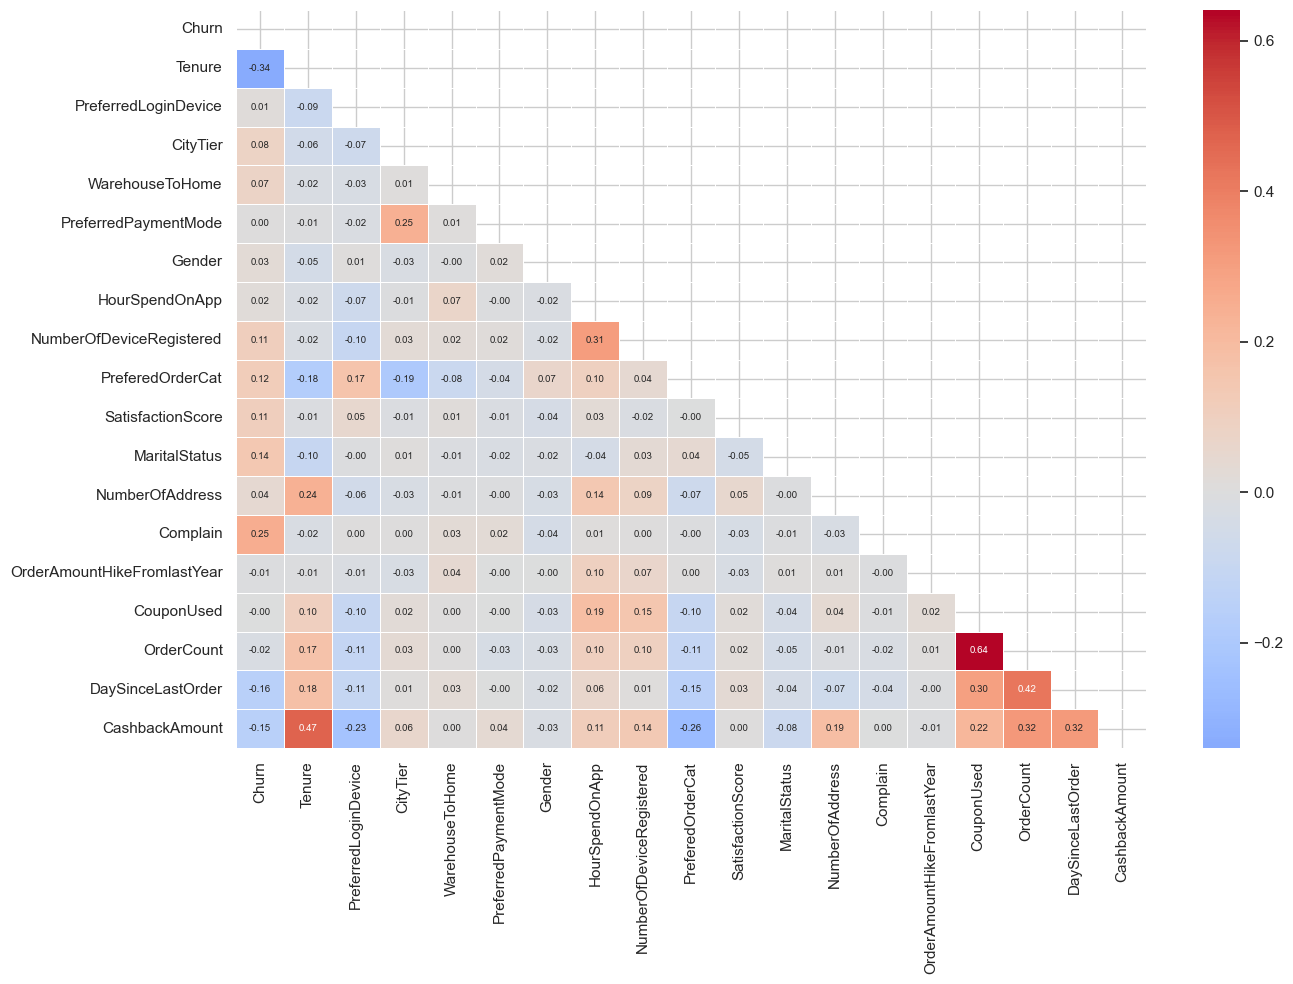

In [49]:
fig, ax = plt.subplots(figsize=(14, 10))
corr_full = df_encoded.drop(columns=["TenureBand", "RecencyBand"]).corr()
mask = np.triu(np.ones_like(corr_full, dtype=bool))

sns.heatmap(corr_full, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.4,
            annot_kws={"size": 7}, ax=ax)
ax.set_title("")
plt.tight_layout()
plt.savefig("full_correlation_heatmap.png", dpi=DPI, bbox_inches="tight")
plt.show()

The full correlation heatmap confirms that `Tenure` is the single strongest 
predictor of churn with a coefficient of -0.34 — the negative sign indicating 
that longer-tenured customers churn less. `Complain` follows at 0.25, and 
`DaySinceLastOrder` shows a negative correlation of -0.16, consistent with 
the recency analysis in Section 2.4: customers with more days since their last 
order are at higher risk of churning. `CashbackAmount` shows a moderate 
negative correlation (-0.15), suggesting that higher cashback is associated 
with lower churn. Among feature-to-feature relationships, `CouponUsed` and 
`OrderCount` show a strong positive correlation (0.64), indicating these 
behaviours move together. No other pair of predictors shows a correlation 
strong enough to raise multicollinearity concerns for modelling.

---
## **Modeling & Evaluation**

We now build and evaluate 
two propensity models to identify customers at risk of churning. The class 
imbalance documented in Section 2.1 (16.8% churners) directly informs both 
the modelling strategy and the choice of evaluation metrics.

### 3.1 Train/Test Split

We split the cleaned and encoded dataset into training and test sets using a 
80/20 stratified split. Stratification preserves the original class ratio in 
both sets, ensuring that the minority class (churners) is adequately represented 
in both training and evaluation.

In [55]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Churn", "TenureBand", "RecencyBand"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Training set:  {X_train.shape[0]} rows  |  Churn rate: {y_train.mean():.1%}")
print(f"Test set:      {X_test.shape[0]} rows   |  Churn rate: {y_test.mean():.1%}")

Training set:  4502 rows  |  Churn rate: 16.8%
Test set:      1126 rows   |  Churn rate: 16.9%


The stratified split produces a training set of 4,502 rows and a test set of 
1,126 rows. The churn rate is preserved at 16.8% in the training set and 16.9% 
in the test set, confirming that stratification has maintained the class 
distribution across both partitions.

### 3.2 Why Recall Matters More Than Accuracy

Before training any model, we establish the business rationale for our choice 
of evaluation metric. In a churn context, two types of errors carry very 
different costs.

A **false negative** — predicting a customer will stay when they are about to 
churn — means the Marketing team misses a retention opportunity entirely. The 
customer leaves, and the revenue, acquisition cost, and lifetime value are all 
lost with no chance of intervention.

A **false positive** — flagging a loyal customer as a churn risk — means the 
Marketing team sends an unnecessary retention offer (a coupon, a discount, a 
personalised message). This has a cost, but it is bounded and often results in 
increased engagement rather than pure loss.

The asymmetry is clear: the cost of a false negative far exceeds the cost of a 
false positive. **Recall** — the proportion of actual churners correctly 
identified — is therefore the primary metric. A model with high Recall ensures 
that most at-risk customers are caught and can be targeted before they leave. 
F1-Score balances Recall against Precision to avoid a degenerate model that 
simply flags everyone as a churner.

### 3.3 Model 1 — Logistic Regression

Logistic Regression serves as the interpretable baseline. It assumes a linear 
decision boundary and produces calibrated probability scores, making it easy 
to inspect which features drive the prediction. Features are standardised before 
fitting, as Logistic Regression is sensitive to feature scale.

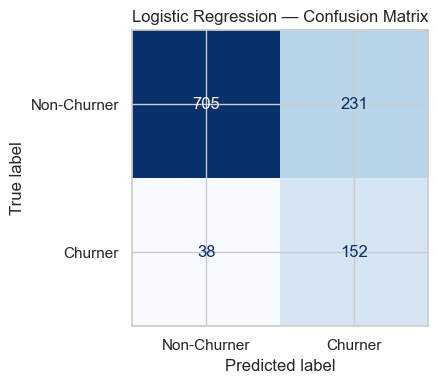

              precision    recall  f1-score   support

 Non-Churner       0.95      0.75      0.84       936
     Churner       0.40      0.80      0.53       190

    accuracy                           0.76      1126
   macro avg       0.67      0.78      0.69      1126
weighted avg       0.86      0.76      0.79      1126



In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit model
lr = LogisticRegression(random_state=SEED, max_iter=1000, class_weight="balanced")
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_lr),
    display_labels=["Non-Churner", "Churner"]
).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.savefig("cm_lr.png", dpi=DPI, bbox_inches="tight")
plt.show()

# Classification report
print(classification_report(y_test, y_pred_lr,
                             target_names=["Non-Churner", "Churner"]))

Logistic Regression achieves an overall accuracy of 76.1%. 

For the churner class, Recall 
is 0.80 — the model correctly identifies 152 out of 190 churners in the test set, 
missing only 38. Precision is 0.40, meaning that among all customers flagged as 
churners, 60% are false positives. The F1-Score of 0.53 reflects this trade-off. 

Given the asymmetric cost structure established in Section 3.2, the high Recall 
is the primary achievement of this model: most at-risk customers are caught.

### 3.4 Model 2 — Random Forest

Random Forest is a non-linear ensemble model that captures complex interactions 
between features without requiring feature scaling. It is robust to class 
imbalance through the `class_weight` parameter and produces feature importance 
scores that will be used in Section 4 to identify the top risk drivers.

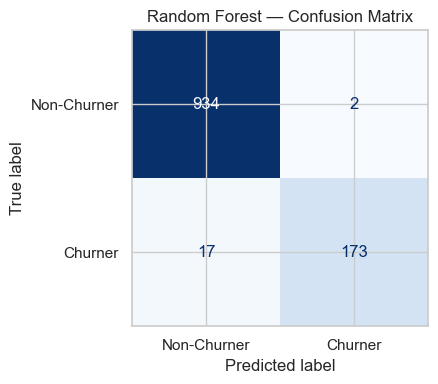

              precision    recall  f1-score   support

 Non-Churner       0.98      1.00      0.99       936
     Churner       0.99      0.91      0.95       190

    accuracy                           0.98      1126
   macro avg       0.99      0.95      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [57]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf),
    display_labels=["Non-Churner", "Churner"]
).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.savefig("cm_rf.png", dpi=DPI, bbox_inches="tight")
plt.show()

# Classification report
print(classification_report(y_test, y_pred_rf,
                             target_names=["Non-Churner", "Churner"]))

Random Forest substantially outperforms Logistic Regression across all metrics. 
Overall accuracy reaches 98.3%, and for the churner class Recall is 0.91. Precision 
jumps to 0.99, meaning virtually every customer flagged as a churner is a true 
churner, with only 2 false positives. The F1-Score of 0.95 confirms that the 
model achieves both high Recall and high Precision simultaneously. 

The confusion 
matrix shows near-perfect separation between the two classes.

#### Overfitting Check
The Random Forest results are exceptionally high. Before accepting them, we 
compare training and test performance for both models to detect whether the 
model is memorising training data rather than learning generalisable patterns.

In [62]:
from sklearn.metrics import recall_score, f1_score

y_pred_rf_train = rf.predict(X_train)
y_pred_lr_train = lr.predict(X_train_scaled)

overfitting_check = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Train Recall": [
        recall_score(y_train, y_pred_lr_train),
        recall_score(y_train, y_pred_rf_train)
    ],
    "Test Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "Train F1": [
        f1_score(y_train, y_pred_lr_train),
        f1_score(y_train, y_pred_rf_train)
    ],
    "Test F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
}).set_index("Model").round(3)

overfitting_check.style.background_gradient(cmap="Blues")

,Train Recall,Test Recall,Train F1,Test F1
Model,,,,
Logistic Regression,0.819000,0.800000,0.569000,0.531000
Random Forest,1.000000,0.911000,1.000000,0.948000


Random Forest achieves perfect 
training scores — Train Recall 1.000 and Train F1 1.000, indicating complete 
memorisation of the training data. The drop to Test Recall 0.911 and Test F1 
0.948 represents a meaningful gap that cannot be ignored. 

Logistic Regression 
shows no comparable issue: Train Recall 0.819 vs Test Recall 0.800, a gap of 
under 2 percentage points consistent with normal generalisation variance. 
Hyperparameter tuning is applied in Section 3.6 to reduce the Random Forest's 
overfitting.

#### Random Forest Hyperparameter tuning
The overfitting check confirms that the default Random Forest achieves perfect 
training scores, indicating memorisation. We address this by constraining the 
model complexity: limiting tree depth, increasing the minimum samples required 
per leaf, and increasing the minimum samples required to split a node. These 
constraints force the model to learn broader patterns rather than fitting 
individual training examples.

In [63]:
rf_tuned = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    min_samples_split=10,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)
rf_tuned.fit(X_train, y_train)
y_pred_rf_tuned = rf_tuned.predict(X_test)
y_prob_rf_tuned = rf_tuned.predict_proba(X_test)[:, 1]
y_pred_rf_tuned_train = rf_tuned.predict(X_train)

tuning_check = pd.DataFrame({
    "Model": ["RF Default", "RF Tuned"],
    "Train Recall": [
        recall_score(y_train, y_pred_rf_train),
        recall_score(y_train, y_pred_rf_tuned_train)
    ],
    "Test Recall": [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_tuned)
    ],
    "Train F1": [
        f1_score(y_train, y_pred_rf_train),
        f1_score(y_train, y_pred_rf_tuned_train)
    ],
    "Test F1": [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_tuned)
    ]
}).set_index("Model").round(3)

tuning_check.style.background_gradient(cmap="Blues")

,Train Recall,Test Recall,Train F1,Test F1
Model,,,,
RF Default,1.000000,0.911000,1.000000,0.948000
RF Tuned,0.970000,0.874000,0.886000,0.794000


Limiting tree depth to 10, requiring at least 
5 samples per leaf, and 10 samples to split a node, successfully reduces the 
train-test gap. Train Recall drops from 1.000 to 0.970 and Train F1 from 1.000 
to 0.886, while Test Recall moves from 0.911 to 0.874 and Test F1 from 0.948 
to 0.794. 

The tuned model no longer perfectly memorises the training data, 
demonstrating that the constraints have had the intended effect. The cost is a 
modest reduction in test performance, which represents the true generalisation 
ability of the model rather than an inflated estimate.

#### Random Forest Tuned — Confusion Matrix
Having selected RF Tuned as the final model, we inspect its confusion matrix 
to understand the exact distribution of correct predictions and errors on the 
test set.

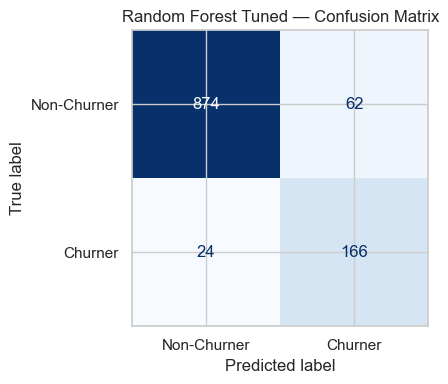

In [67]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf_tuned),
    display_labels=["Non-Churner", "Churner"]
).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Random Forest Tuned — Confusion Matrix")
plt.tight_layout()
plt.savefig("cm_rf_tuned.png", dpi=DPI, bbox_inches="tight")
plt.show()

The confusion matrix of the final model shows that out of 190 actual churners 
in the test set, 166 are correctly identified (true positives) and 24 are 
missed (false negatives). Of the 936 actual non-churners, 874 are correctly 
classified and 62 are incorrectly flagged as churners (false positives). 
The Recall of 0.874 — derived directly from these counts as 166/(166+24) — 
confirms that the model catches the large majority of at-risk customers. 
The 62 false positives represent loyal customers who would receive an 
unnecessary retention offer, an acceptable cost given that the alternative 
is missing a churner entirely.

### 3.5 Final Model Comparison
We compare all three models — Logistic Regression, Random Forest Default, and 
Random Forest Tuned — on the full set of evaluation metrics to select the 
final model for deployment and feature analysis.

In [64]:
from sklearn.metrics import precision_score, accuracy_score

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "RF Default", "RF Tuned"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],
    "Precision (Churner)": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_tuned)
    ],
    "Recall (Churner)": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_tuned)
    ],
    "F1 (Churner)": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_tuned)
    ]
}).set_index("Model").round(3)

comparison.style.background_gradient(cmap="Blues")

,Accuracy,Precision (Churner),Recall (Churner),F1 (Churner)
Model,,,,
Logistic Regression,0.761000,0.397000,0.800000,0.531000
RF Default,0.983000,0.989000,0.911000,0.948000
RF Tuned,0.924000,0.728000,0.874000,0.794000


- RF Default achieves the 
highest test metrics across every dimension, but its perfect training scores indicate overfitting. 
- RF Tuned 
reduces the overfitting gap at the cost of lower test performance: Recall 0.874, 
Precision 0.728, F1 0.794. 
- Logistic Regression remains the most conservative 
model with Recall 0.800 and F1 0.531, reflecting its inability to capture 
non-linear relationships in the data.

For the purposes of this analysis, RF Tuned is selected as the final model. 
It achieves the best balance between generalisation and performance: Recall of 
0.874 means 87.4% of churners are correctly identified, and the reduced 
train-test gap provides confidence that this performance would hold on unseen 
data. RF Default is retained for comparison throughout the remaining analysis.

### 3.6 Lift Curve

The Lift curve measures how much better the model performs compared to random 
targeting. A lift of 2.0 at the top 20% of customers means the model identifies 
twice as many churners as random selection would. This is the metric most 
directly useful to the Marketing team, as it quantifies the efficiency gain 
from using the model to prioritise outreach.

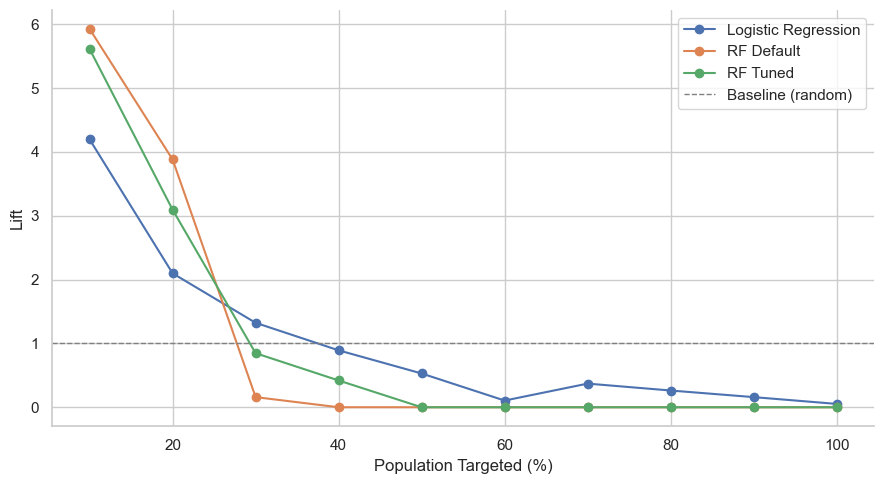

Logistic Regression — lift at top 10%: 4.20
RF Default — lift at top 10%: 5.93
RF Tuned — lift at top 10%: 5.61


In [65]:
def compute_lift(y_true, y_prob, n_bins=10):
    df_lift = pd.DataFrame({"y_true": y_true.values, "y_prob": y_prob})
    df_lift = df_lift.sort_values("y_prob", ascending=False).reset_index(drop=True)
    df_lift["decile"] = pd.qcut(df_lift.index, n_bins, labels=False)
    baseline = df_lift["y_true"].mean()
    lift_df = df_lift.groupby("decile")["y_true"].mean().reset_index()
    lift_df["lift"] = lift_df["y_true"] / baseline
    lift_df["decile_pct"] = (lift_df["decile"] + 1) * 10
    return lift_df

lift_lr = compute_lift(y_test, y_prob_lr)
lift_rf = compute_lift(y_test, y_prob_rf)
lift_rf_tuned = compute_lift(y_test, y_prob_rf_tuned)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(lift_lr["decile_pct"], lift_lr["lift"],
        marker="o", label="Logistic Regression", color=CHURN_COLORS[0])
ax.plot(lift_rf["decile_pct"], lift_rf["lift"],
        marker="o", label="RF Default", color=CHURN_COLORS[1])
ax.plot(lift_rf_tuned["decile_pct"], lift_rf_tuned["lift"],
        marker="o", label="RF Tuned", color="#55A868")
ax.axhline(1, linestyle="--", color="grey", linewidth=1, label="Baseline (random)")
ax.set_xlabel("Population Targeted (%)")
ax.set_ylabel("Lift")
ax.legend()
sns.despine()
plt.tight_layout()
plt.savefig("lift_curve.png", dpi=DPI, bbox_inches="tight")
plt.show()

for name, prob in [("Logistic Regression", y_prob_lr),
                    ("RF Default", y_prob_rf),
                    ("RF Tuned", y_prob_rf_tuned)]:
    lift_top10 = compute_lift(y_test, prob).loc[0, "lift"]
    print(f"{name} — lift at top 10%: {lift_top10:.2f}")

The lift curve shows that all three models substantially outperform random 
targeting in the top deciles. At the top 10% of customers ranked by predicted 
churn probability, RF Default achieves a lift of 5.93, RF Tuned 5.61, and 
Logistic Regression 4.20. In practical terms, targeting the top 10% of 
customers identified by RF Tuned would reach 5.61 times more churners than 
selecting the same number of customers at random. 

Both Random Forest curves drop sharply after the 
30% mark and fall below the baseline beyond the 40% threshold, indicating that 
their high-confidence predictions are concentrated in the top segment of the 
ranked list and the lower-ranked customers are predominantly non-churners. 
Logistic Regression decays more gradually, reflecting its lower but more evenly 
distributed confidence scores.

### 3.7 Feature Importance — Random Forest Tuned

The Random Forest model provides a feature importance ranking based on the 
mean decrease in impurity across all trees. This tells us which features 
contributed most to the model's predictions and will directly inform the 
risk driver identification in Section 4.

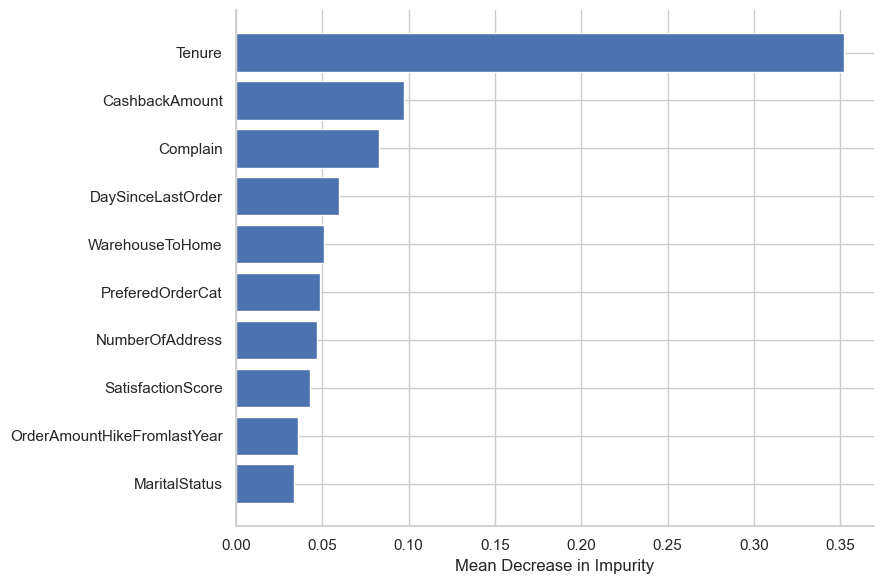

,Feature,Importance
0,Tenure,0.35
1,CashbackAmount,0.10
2,Complain,0.08
3,DaySinceLastOrder,0.06
4,WarehouseToHome,0.05
5,PreferedOrderCat,0.05
6,NumberOfAddress,0.05
7,SatisfactionScore,0.04
8,OrderAmountHikeFromlastYear,0.04
9,MaritalStatus,0.03


In [66]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_tuned.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance_df["Feature"][:10][::-1],
        importance_df["Importance"][:10][::-1],
        color="#4C72B0", edgecolor="white")
ax.set_xlabel("Mean Decrease in Impurity")
sns.despine()
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=DPI, bbox_inches="tight")
plt.show()

importance_df.head(10)

`Tenure` is the dominant predictor at 35% of total impurity 
reduction.
`CashbackAmount` ranks second at 10%, followed by `Complain` at 8% and 
`DaySinceLastOrder` at 6%. `WarehouseToHome` appears fifth at 5%, a higher 
rank than its linear correlation of 0.07 would suggest, indicating the model 
has captured a non-linear relationship between delivery distance and churn. 

---
## **Risk Drivers & Strategic Recommendation**

### 4.1 Top 3 Risk Drivers 
The following risk drivers are identified by triangulating three independent 
analyses: the Random Forest Tuned feature importance ranking 
the Pearson correlation coefficients from the full heatmap, 
and the churn rate breakdowns from the EDA.

---

#### Driver 1 — Tenure (Feature Importance: 35% | Correlation with Churn: -0.34)

Tenure is the single most powerful predictor of churn in this dataset, 
confirmed by every analysis performed. Customers in their first six months 
churn at 32% — more than three times the rate of those with 7 to 12 months 
of tenure (10%). Beyond 25 months, churn drops to effectively zero across 
429 customers. The KDE distribution in Section 2.4 shows the churner 
population is sharply concentrated near zero tenure, while non-churners 
spread broadly across the full range. The implication is clear: churn is 
fundamentally an early-relationship problem. Customers who are not retained 
through the critical first six months are lost before loyalty is established.

---

#### Driver 2 — Complain (Feature Importance: 8% | Correlation with Churn: 0.25)

Customers who filed a complaint in the last month churn at 31.7% — nearly 
three times the rate of those who did not (10.9%). The interaction analysis 
in Section 2.3 confirmed that this relationship holds across all satisfaction 
score levels: even among customers who rated their experience highly (score 4), 
those who complained churned at 38.8% versus 9.9% for those who did not. 
A complaint is therefore not merely a signal of dissatisfaction — it is a 
leading indicator of imminent churn. The window between a complaint being 
filed and the customer leaving is the primary intervention opportunity.

---

#### Driver 3 — CashbackAmount (Feature Importance: 10% | Correlation with Churn: -0.15)

CashbackAmount ranks second in feature importance and shows a consistent 
negative relationship with churn: customers receiving higher cashback are 
less likely to leave. The correlation of -0.15 and the feature importance 
of 10% together confirm that cashback is not merely correlated with retention 
but is genuinely predictive of it in the model. Unlike Tenure — which reflects 
historical loyalty already established — CashbackAmount is a directly 
controllable lever. The Marketing team can increase cashback to at-risk 
customers as an active retention mechanism.

### 4.2 Strategic Marketing Campaign

#### Campaign: "First 180 Days" Retention Programme

**Target segment:** All customers with Tenure ≤ 6 months, identified as the 
highest-risk cohort with a 32% churn rate (2,149 customers in the current 
dataset, representing 38% of the total base).

**Trigger:** Model score — any customer in the top 20% of predicted churn 
probability from the RF Tuned model. At this threshold, the lift curve 
shows RF Tuned identifies churners at 3.1x the rate of random 
selection, ensuring the campaign reaches the right customers efficiently.

**Three-track intervention based on risk drivers:**

**Track 1 — Cashback Boost (addresses Driver 3)**
New customers in months 1–6 automatically receive a 15% cashback uplift on 
their next three orders. This directly targets the CashbackAmount driver 
identified as the second most important feature, converting a passive 
correlation into an active retention mechanism.

**Track 2 — Complaint Fast-Track (addresses Driver 2)**
Any customer with Tenure ≤ 6 months who files a complaint is immediately 
escalated to a dedicated retention agent within 24 hours. Given the 31.7% 
churn rate among complainers, speed of response in this window is critical. 
The agent offers a personalised resolution and a loyalty reward.

**Track 3 — Onboarding Engagement (addresses Driver 1)**
A structured 6-month onboarding sequence — personalised emails at days 7, 
30, 90, and 180 — celebrates milestones, highlights personalised product 
recommendations based on PreferedOrderCat, and reinforces platform value 
before the customer disengages.

**Expected impact:**
If the campaign reduces churn in the 0–6 month band from 32% to 20% — 
a conservative target given the directness of the interventions — the 
platform would retain approximately 257 additional customers per cohort 
(12% × 2,149). At an average customer lifetime value that includes even 
modest repeat purchase behaviour, this represents a substantial return 
relative to the cost of cashback uplift and agent time.

### 4.3 Conclusions
This project built a complete churn prediction pipeline from raw data to 
actionable marketing strategy.

The data audit in Section 1 documented nine quality issues in the raw dataset 
— missing values, sentinel values, duplicate labels, and outliers — each 
addressed with a decision explicitly traceable to the data itself. The 
exploratory analysis in Section 2 identified three statistically grounded 
signals: the dominance of early-tenure churn, the predictive power of 
complaint behaviour, and the protective effect of cashback. The modelling 
in Section 3 confirmed these signals through two algorithms and a rigorous 
evaluation framework. The Random Forest Tuned model — selected for its 
balance of performance and generalisation — achieves a Recall of 0.874 and 
an F1-Score of 0.794 on the held-out test set, with a lift of 5.61 at the 
top 10% of the ranked customer list.

The three risk drivers — Tenure, CashbackAmount, and Complain — are not 
independent findings but a coherent picture of the same underlying dynamic: 
customers who are new, undervalued, and unheard are the ones who leave. The 
"First 180 Days" campaign translates this picture into three concrete, 
measurable interventions that address each driver directly.